# Part 1

> In the figure below, four points are arranged in a square. The top two points can each be labeled with one of eight letters: A, B, C, D, E, F, G, and H. The bottom two points can each be labeled with one of three three letters: J, K, and L. (Hence the numbers “8” and “3” in the figure.)

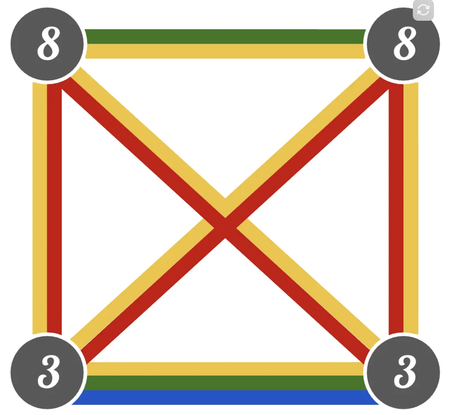

> You are labeling _exactly two_ of the points with letters. The other two points will remain blank.
>
> Once you’ve labeled two points, you must choose one of the colored connectors (yellow, red, green, or blue) between the two points you labeled—note carefully where each color connector is in the diagram. But there are some more rules:
>
> - If the two letters are the same, you cannot use a yellow connector.
> - The blue connector is only an option when the bottom points have _the same letter_.
>
> Finally, two diagrams are equivalent if they are reflections of each other. For example, the following two diagrams are equivalent:

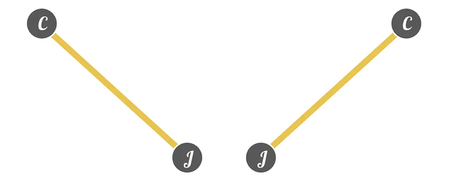

> All told, how many distinct (non-equivalent) diagrams can you make?


# Solution


In [82]:
from collections import defaultdict
from math import sqrt

NODE_TO_VALS = {0: "ABCDEFGH", 1: "ABCDEFGH", 2: "JKL", 3: "JKL"}
COLORS_BY_EDGE_NUM = {0: "GY", 1: "YR", 2: "YR", 3: "YR", 4: "YR", 5: "YGB"}
EDGE_TO_NODES = {
    0: (0, 1),
    1: (0, 2),
    2: (0, 3),
    3: (1, 2),
    4: (1, 3),
    5: (2, 3),
}
EDGE_SYMS = {0: 0, 1: 4, 2: 3, 3: 2, 4: 1, 5: 5}
SELF_SYM_EDGES = [0, 5]
COLOR_TO_POINTS = {"g": 0, "Y": 1, "R": sqrt(2), "G": sqrt(3), "B": sqrt(6)}


class Diagram:
    """
    A diagram is represented as a list of node labels, and edge, and color
    Here the nodes of the square are in a list and go CW starting at top left
    """

    def __init__(self, nodes, edge, edge_color):
        self.nodes = nodes
        self.edge = edge
        self.edge_color = edge_color

    def is_valid(self):
        node1, node2 = [
            self.nodes[i] for i in range(4) if i in EDGE_TO_NODES[self.edge]
        ]
        if self.edge_color == "Y":
            return node1 != node2
        if self.edge_color == "B":
            return node1 == node2
        return True

    def build_symmetric_diagram(self):
        new_edge = EDGE_SYMS[self.edge]  # the edge that is the reflected one

        node1, node2 = EDGE_TO_NODES[new_edge]
        if new_edge in SELF_SYM_EDGES:
            node1, node2 = node2, node1

        new_nodes = [""] * 4
        prev_node1, prev_node2 = EDGE_TO_NODES[self.edge]  # old node locations
        new_nodes[node1] = self.nodes[prev_node1]  # assign labels to the new positions
        new_nodes[node2] = self.nodes[prev_node2]
        sym_diagram = Diagram(new_nodes, new_edge, self.edge_color)
        return sym_diagram

    def __eq__(self, other_diagram):
        if not isinstance(other_diagram, Diagram):
            return False
        nodes_match = self.nodes == other_diagram.nodes
        edges_match = self.edge == other_diagram.edge
        colors_match = self.edge_color == other_diagram.edge_color
        return nodes_match and edges_match and colors_match

    def __hash__(self):
        return hash((tuple(self.nodes), self.edge, self.edge_color))

    def __repr__(self):
        return f"{self.nodes, EDGE_TO_NODES[self.edge], self.edge_color}"

    def get_score(self):
        n1, n2 = EDGE_TO_NODES[self.edge]

        letter1, letter2 = self.nodes[n1], self.nodes[n2]
        if self.edge_color == "B" and letter1 != letter2:
            return 0
        return COLOR_TO_POINTS[self.edge_color]


unique_diagrams = set()
diagrams_by_color = defaultdict(list)
for edge, (n1, n2) in EDGE_TO_NODES.items():
    for color in COLORS_BY_EDGE_NUM[edge]:
        for val1 in NODE_TO_VALS[n1]:
            for val2 in NODE_TO_VALS[n2]:
                nodes = [""] * 4
                nodes[n1], nodes[n2] = val1, val2
                cur_diagram = Diagram(nodes, edge, color)
                if not cur_diagram.is_valid():
                    continue
                sym_diagram = cur_diagram.build_symmetric_diagram()
                if sym_diagram in unique_diagrams:
                    continue
                unique_diagrams.add(cur_diagram)
                diagrams_by_color[color].append(cur_diagram)

for color in diagrams_by_color:
    print(f"there are {len(diagrams_by_color[color])} diagrams with the color {color} ")
print(len(unique_diagrams))

there are 42 diagrams with the color G 
there are 79 diagrams with the color Y 
there are 48 diagrams with the color R 
there are 3 diagrams with the color B 
172


We can see this gives us $\boxed{172}$ unique diagrams. This can also be done by hand but the infrastructure here will be useful for the next part.


# Part 2

> Next, it’s time for a little game. Let’s continue with the list of distinct diagrams you just found for this week’s Fiddler, being sure to choose exactly one representative from each pair of reflected diagrams. And further suppose every diagram in your list actually contains _four_ letters: In addition to the two “visible” letters in the diagram, the remaining two points each have a “secret” letter—8 possible letters (A through H) for a point on top and 3 possible letters (J through L) for a point on the bottom—that are fixed for a given diagram. The top and bottom letters are chosen with replacement, so that a letter can occur more than once.
>
> So here’s the game: In each round, you are randomly generating a new diagram. This time, the top two points are each randomly labeled with one of _nine_ letters: A, B, C, D, E, F, G, H, and I. The bottom two points are each randomly labeled with one of _four_ letters: J, K, L, and M. Letters are chosen independently and with replacement. Once these letters are assigned, you randomly pick two points whose letters are “secret.”
>
> Between the remaining two “visible” letters, you randomly pick from among the _four_ connectors between them shown in the diagram below:

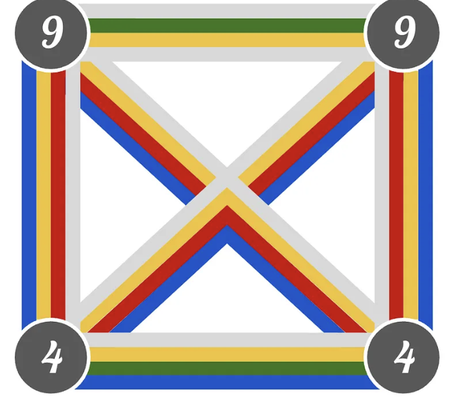

> While there are indeed four connectors between any two points, there are five connector types. Here are the point values associated with each type:
>
> - A gray connector is worth 0 points
> - A yellow connector is worth 1 point.
> - A red connector is worth $\sqrt{2}$ points.
> - A green connector is worth $\sqrt{3}$ points.
> - A blue connector is worth $\sqrt{6}$ points if it connects identical letters—otherwise, it’s worth 0 points.
>
> Now, you earn points when your randomly generated diagram perfectly matches one of the distinct diagrams from your list, including: the four letters, which letters are visible, their orientation (no reflections allowed this time!), and the color of the connector between the visible letters. If there is indeed a diagram that’s a perfect match, you get the number of points corresponding to its connector. Otherwise, you get no points.
>
> On average, how many rounds of this game can you expect to play for each point that you earn?


# Solution

Now we have to make each of our grids into a "representitive" grid.
Go back through our list, assign values to the missing representatives. Now we have a cannonical set.

We can generate many random sample grids and see how many points


In [83]:
from random import choice

NODE_TO_VALS2 = {0: "ABCDEFGHI", 1: "ABCDEFGHI", 2: "JKLM", 3: "JKLM"}

COLORS_BY_EDGE_NUM2 = {0: "GYgg", 1: "YBRg", 2: "YBRg", 3: "YBRg", 4: "YBRg", 5: "YGBg"}


def build_canonical_set(unique_diagrams):
    canonical_set = set()
    for cur_diagram in unique_diagrams:
        new_nodes = [
            n if n != "" else choice(NODE_TO_VALS[i])
            for i, n in enumerate(cur_diagram.nodes)
        ]
        cur_diagram.nodes = new_nodes
        canonical_set.add(cur_diagram)
    return canonical_set


def get_random_diagram():
    nodes = [choice(NODE_TO_VALS2[i]) for i in range(4)]
    edge = choice(range(6))
    color = choice(COLORS_BY_EDGE_NUM2[edge])
    return Diagram(nodes, edge, color)

We are now poised to do some monte-carlo simulation. We can generate a canonical set and then produce random diagrams and score them against it.
We then take the empirical value of games / points scored.


In [85]:
canonical_set = build_canonical_set(unique_diagrams)
NUM_TRIALS = 2 * 10**9
total_score = 0
for _ in range(NUM_TRIALS):
    D = get_random_diagram()
    if D.edge_color == "g":
        continue
    if D in canonical_set:
        d_score = D.get_score()
        total_score += d_score

print(NUM_TRIALS / total_score)

137.03975213425232


Note, this is very close to the reciprocal of [fine structure constant](https://en.wikipedia.org/wiki/Fine-structure_constant) $\frac{1}{\alpha} \approx 137.035999$. This, in conjunction with the puzzles's name _seeking alpha_ and the mentioning of the fine-structure constant in the bonus puzzle section, leads me to believe the answer is approximately $\boxed{\frac{1}{\alpha} \approx 137.03}$.
